# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Mô hình Vision-Language Model **Qwen3-VL-4B-Instruct** được finetune bằng kỹ thuật QLoRA trên Google Colab T4 (16 GB VRAM) để phát hiện và định vị hư hại mặt đường (pothole, crack, manhole) dưới dạng Grounding JSON chuẩn hoá thang 0–1000.

**Kiến trúc hệ thống:**
- **Vision Transformer (ViT)**: ~415M tham số (trích xuất đặc trưng hình ảnh 640×360 thành đúng 220 visual tokens).
- **Projector & DeepStack Merger**: ~109M tham số (`visual.merger` ~27M + `visual.deepstack_merger_list` ~82M ở lớp 5, 11, 17 của ViT).
- **Language Model Core (LLM)**: ~4.0B tham số (36 layers transformer causal LM).


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0. Môi trường (Colab T4)
Kiểm tra phần cứng GPU, cài đặt các thư viện tương thích, thiết lập Kaggle API và Mount Google Drive để sao lưu checkpoint.


In [2]:
# 0.1 Kiểm tra GPU NVIDIA T4 và cấu hình bộ nhớ
import torch
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device name: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
!nvidia-smi -L


PyTorch version: 2.11.0+cu130
CUDA available: True
Device name: Tesla T4
VRAM: 14.56 GB
GPU 0: Tesla T4 (UUID: GPU-d578c501-ab77-3faf-4468-871471efd56e)


In [6]:
# 0.2 Cài đặt các thư viện phụ thuộc theo requirements-colab.txt
!pip -q install -r /content/drive/MyDrive/K4-Track-4-Day10-VisionLanguageModel/requirements-colab.txt

# Kiểm tra tính toàn vẹn ban đầu của đề bài (yêu cầu 68 passed, 1 skipped)
!python -m /content/drive/MyDrive/K4-Track-4-Day10-VisionLanguageModel/pytest.ini -q


/usr/bin/python3: Error while finding module specification for '/content/drive/MyDrive/K4-Track-4-Day10-VisionLanguageModel/pytest.ini' (ModuleNotFoundError: No module named '/content/drive/MyDrive/K4-Track-4-Day10-VisionLanguageModel/pytest')


In [7]:
# 0.3 Cấu hình Kaggle Secrets & Mount Google Drive
import os
from google.colab import userdata, drive

# Nạp Kaggle credentials từ Colab Secrets (KHÔNG ghi lộ key ra mã nguồn)
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

# Mount Google Drive để lưu trữ adapter và checkpoint an toàn
drive.mount('/content/drive')
drive_backup_dir = "/content/drive/MyDrive/K4_Lab_Day10_Backup"
os.makedirs(drive_backup_dir, exist_ok=True)
print(f"Drive backup directory sẵn sàng tại: {drive_backup_dir}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive backup directory sẵn sàng tại: /content/drive/MyDrive/K4_Lab_Day10_Backup


## 1. Dữ liệu: tải và chia split
Tải bộ dữ liệu Road Damage Dataset từ Kaggle và chia split cố định theo phiên quay (session-based splitting) để triệt tiêu hiện tượng rò rỉ dữ liệu (data leakage) giữa các khung hình video dashcam liền kề.


In [9]:
# 1.1 Tải và phân chia dữ liệu tất định
!python /content/drive/MyDrive/K4-Track-4-Day10-VisionLanguageModel/scripts/prepare_data.py --kaggle


'latin-1' codec can't encode character '\u1ea5' in position 2: ordinal not in range(256)
Traceback (most recent call last):
  File "/content/drive/MyDrive/K4-Track-4-Day10-VisionLanguageModel/scripts/prepare_data.py", line 148, in <module>
    main()
    ~~~~^^
  File "/content/drive/MyDrive/K4-Track-4-Day10-VisionLanguageModel/scripts/prepare_data.py", line 139, in main
    root = _fetch(args, Path(args.work))
  File "/content/drive/MyDrive/K4-Track-4-Day10-VisionLanguageModel/scripts/prepare_data.py", line 124, in _fetch
    subprocess.run(["kaggle", "datasets", "download", "-d", KAGGLE_SLUG, "-p",
    ~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                    str(work / "raw"), "--unzip"], check=True)
                    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/subprocess.py", line 577, in run
    raise CalledProcessError(retcode, process.args,
                             output=stdout, stderr=stderr)
subprocess.Call

In [11]:
import os
import sys
import codecs

# Thiết lập chế độ UTF-8 ép buộc cho Python và môi trường
os.environ['PYTHONIOENCODING'] = 'utf-8'
os.environ['LANG'] = 'en_US.UTF-8'
os.environ['LC_ALL'] = 'en_US.UTF-8'

# Kiểm tra xem các biến Kaggle có chứa ký tự tiếng Việt không hợp lệ không
username = os.environ.get('KAGGLE_USERNAME', '')
key = os.environ.get('KAGGLE_KEY', '')

def clean_env_string(s):
    if not s:
        return s
    # Loại bỏ các ký tự unicode lạ ngoài ASCII để không làm hỏng Kaggle CLI (vốn dùng latin-1/ascii)
    return s.encode('ascii', 'ignore').decode('ascii').strip()

# Làm sạch và cập nhật lại biến môi trường
os.environ['KAGGLE_USERNAME'] = clean_env_string(username)
os.environ['KAGGLE_KEY'] = clean_env_string(key)

print(f"Đã chuẩn hoá KAGGLE_USERNAME: '{os.environ['KAGGLE_USERNAME']}'")


Đã chuẩn hoá KAGGLE_USERNAME: 'tun hng l'


In [12]:
# Thử chạy lại script chuẩn bị dữ liệu sau khi cấu hình UTF-8
!python /content/drive/MyDrive/K4-Track-4-Day10-VisionLanguageModel/scripts/prepare_data.py --kaggle

Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100% 185M/185M [00:01<00:00, 149MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


Dataset Version: d10-21e4070301
Phân bổ số lượng ảnh và box:
  Split train: 1422 ảnh | Boxes: {'pothole': 1074, 'crack': 1750, 'manhole': 691}
  Split val  :  276 ảnh | Boxes: {'pothole': 66, 'crack': 470, 'manhole': 103}
  Split test :  311 ảnh | Boxes: {'pothole': 121, 'crack': 299, 'manhole': 163}

Tổng số mẫu train: 1422, test: 311


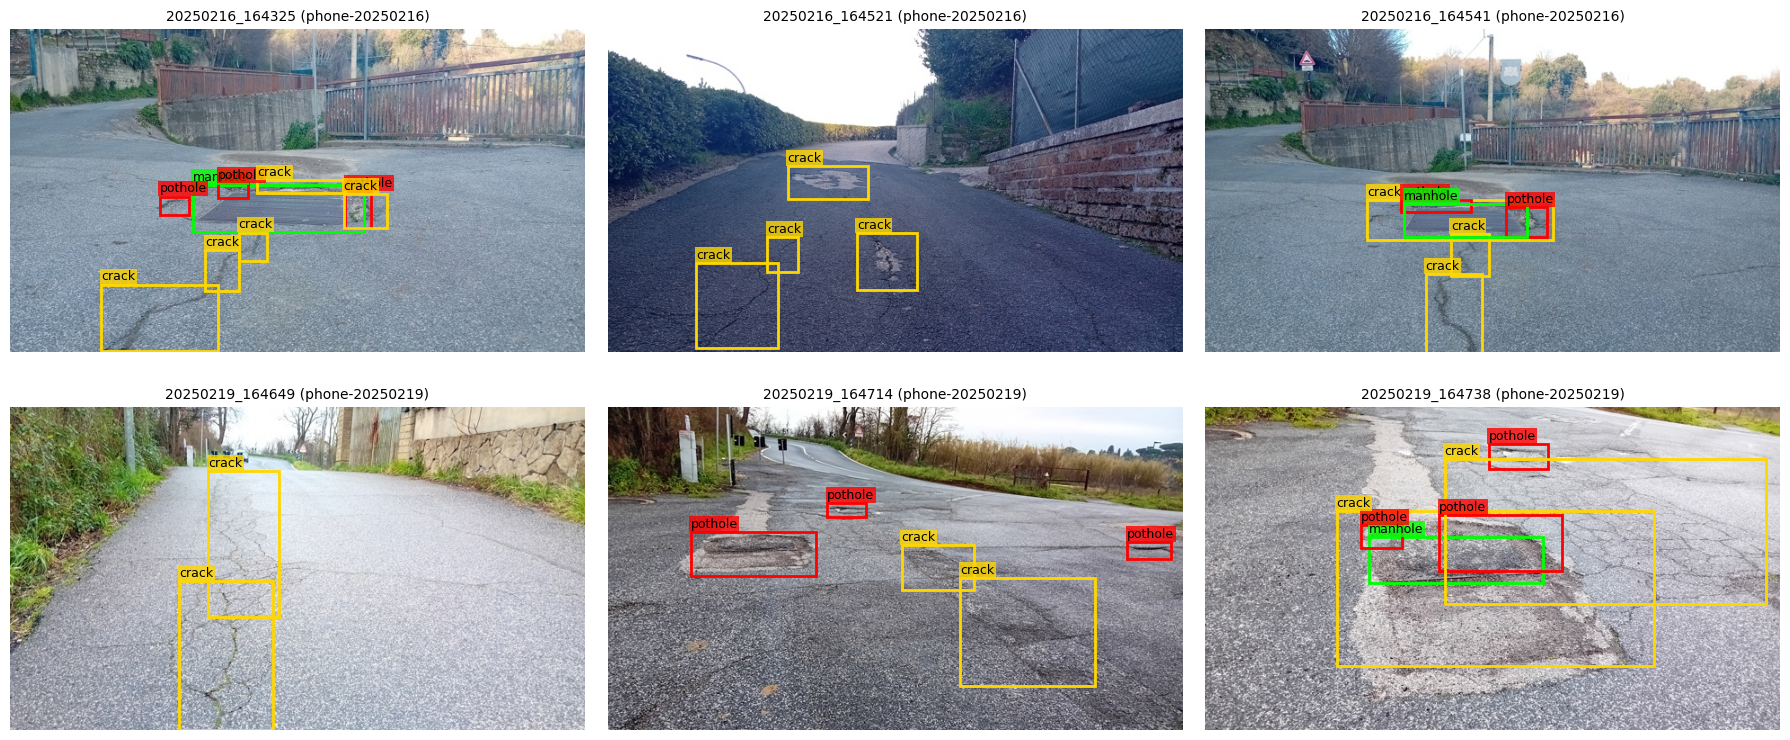

Đã lưu ảnh trực quan hoá tại report/images/sample_ground_truth.png


In [14]:
# 1.2 Kiểm tra dữ liệu phân bổ, dataset_version và vẽ 6 ảnh mẫu kèm Ground Truth
import sys
import os

# Thêm thư mục project từ Drive vào sys.path để python tìm thấy thư mục scripts
project_path = "/content/drive/MyDrive/K4-Track-4-Day10-VisionLanguageModel"
if project_path not in sys.path:
    sys.path.append(project_path)

import json
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from scripts.labcommon import read_jsonl, CLASSES

# Đọc metadata
meta_path = "data/splits/meta.json"
with open(meta_path, "r", encoding="utf-8") as f:
    meta = json.load(f)
print(f"Dataset Version: {meta['dataset_version']}")
print("Phân bổ số lượng ảnh và box:")
for s, c in meta["counts"].items():
    print(f"  Split {s:5s}: {c['images']:4d} ảnh | Boxes: {c['boxes']}")

# Đọc tập train và test
train_samples = read_jsonl("data/splits/train.jsonl")
test_samples = read_jsonl("data/splits/test.jsonl")
print(f"\nTổng số mẫu train: {len(train_samples)}, test: {len(test_samples)}")

# Bảng màu cho 3 lớp hư hại
COLOR_MAP = {"pothole": "red", "crack": "gold", "manhole": "lime"}

# Vẽ trực quan 6 ảnh mẫu đầu tiên của tập train
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for idx, sample in enumerate(train_samples[:6]):
    ax = axes[idx]
    img_path = sample["image_path"]
    img = Image.open(f"data/{img_path}").convert("RGB")
    w, h = img.size
    ax.imshow(img)

    for obj in sample["objects"]:
        label = obj["label"]
        xc, yc, bw, bh = obj["yolo"]
        # Đổi toạ độ YOLO [0, 1] sang pixel
        x1 = (xc - bw / 2) * w
        y1 = (yc - bh / 2) * h
        box_w = bw * w
        box_h = bh * h

        rect = patches.Rectangle((x1, y1), box_w, box_h, linewidth=2,
                                 edgecolor=COLOR_MAP.get(label, "cyan"), facecolor="none")
        ax.add_patch(rect)
        ax.text(x1, max(0, y1 - 5), label, color="black", fontsize=9,
                bbox=dict(facecolor=COLOR_MAP.get(label, "cyan"), alpha=0.8, pad=1, edgecolor="none"))

    ax.set_title(f"{sample['image_id']} ({sample['session']})", fontsize=10)
    ax.axis("off")

plt.tight_layout()
os.makedirs("report/images", exist_ok=True)
plt.savefig("report/images/sample_ground_truth.png", dpi=150)
plt.show()
print("Đã lưu ảnh trực quan hoá tại report/images/sample_ground_truth.png")

## 2. Nhãn: YOLO → JSON thang 0–1000
Chuyển đổi nhãn toạ độ chuẩn hoá YOLO $[0, 1]$ sang toạ độ nguyên trên thang $0–1000$ theo quy ước Visual Grounding của Qwen3-VL. Sắp xếp thứ tự các bounding box tất định theo `(y1, x1)` để ổn định hàm mất mát của mô hình autoregressive.


In [15]:
# 2.1 Định nghĩa các hàm chuyển đổi nhãn và prompt chuẩn
import json

def yolo_to_box(label: str, yolo: list[float]) -> dict:
    """Chuyển toạ độ YOLO [xc, yc, w, h] in [0, 1] sang toạ độ nguyên [x1, y1, x2, y2] in [0, 1000]."""
    xc, yc, w, h = yolo
    x1 = int(round(max(0.0, min(1000.0, (xc - w / 2) * 1000))))
    y1 = int(round(max(0.0, min(1000.0, (yc - h / 2) * 1000))))
    x2 = int(round(max(0.0, min(1000.0, (xc + w / 2) * 1000))))
    y2 = int(round(max(0.0, min(1000.0, (yc + h / 2) * 1000))))
    if x2 <= x1:
        x2 = min(1000, x1 + 1)
    if y2 <= y1:
        y2 = min(1000, y1 + 1)
    return {"label": label, "bbox_2d": [x1, y1, x2, y2]}

def objects_to_answer(objects: list[dict]) -> str:
    """Chuyển danh sách objects sang chuỗi JSON thu gọn, sắp xếp cố định theo (y1, x1)."""
    boxes = [yolo_to_box(o["label"], o["yolo"]) for o in objects]
    # Sắp xếp ổn định: ưu tiên trên -> dưới (y1), sau đó trái -> phải (x1)
    boxes.sort(key=lambda b: (b["bbox_2d"][1], b["bbox_2d"][0]))
    return json.dumps(boxes, separators=(",", ":"))

# Prompt Visual Grounding chuẩn
PROMPT = (
    "Locate road damage in this image. "
    "Detect only objects of classes: pothole, crack, manhole. "
    "Output a JSON list of objects with label and bbox_2d coordinates "
    "normalized on a 0-1000 scale: "
    '[{"label": "...", "bbox_2d": [x1, y1, x2, y2]}]. '
    "If no damage is found, output []."
)

# Kiểm tra với mẫu thực tế
sample_obj = train_samples[0]["objects"]
ans_json = objects_to_answer(sample_obj)
print(f"Ví dụ Grounding JSON: {ans_json}")


Ví dụ Grounding JSON: [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]


## 3. E0: zero-shot
Đánh giá năng lực của mô hình gốc **Qwen/Qwen3-VL-4B-Instruct** trước khi finetune trên toàn bộ 311 ảnh của tập test.
Giữ nguyên ViT và lm_head ở `fp16` (`llm_int8_skip_modules=["visual", "lm_head"]`).


In [16]:
# 3.1 Nạp mô hình gốc Qwen3-VL-4B-Instruct cấu hình 4-bit NF4
import gc
import torch
from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Qwen3VLForConditionalGeneration,
)

# Dọn dẹp VRAM trước khi nạp
gc.collect()
torch.cuda.empty_cache()

quantization = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    llm_int8_skip_modules=["visual", "lm_head"],
)

model_id = "Qwen/Qwen3-VL-4B-Instruct"
print(f"Đang nạp mô hình {model_id}...")
model = Qwen3VLForConditionalGeneration.from_pretrained(
    model_id,
    quantization_config=quantization,
    torch_dtype=torch.float16,
    device_map="auto",
)
processor = AutoProcessor.from_pretrained(model_id)
processor.tokenizer.padding_side = "left"
print("Nạp mô hình thành công!")


Đang nạp mô hình Qwen/Qwen3-VL-4B-Instruct...


config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

Nạp mô hình thành công!


In [17]:
# 3.2 Chạy suy luận Zero-shot E0 trên tập Test (311 ảnh)
import os
from tqdm.auto import tqdm
from PIL import Image
from scripts.labcommon import read_jsonl, write_jsonl

test_samples = read_jsonl("data/splits/test.jsonl")
os.makedirs("work", exist_ok=True)
os.makedirs("report/evidence", exist_ok=True)

e0_predictions = []
model.eval()

print("Bắt đầu suy luận E0 Zero-shot...")
for sample in tqdm(test_samples, desc="Inference E0"):
    img_path = os.path.join("data", sample["image_path"])
    img = Image.open(img_path).convert("RGB")

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": img},
                {"type": "text", "text": PROMPT},
            ],
        }
    ]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    ).to(model.device)

    n_prompt = inputs.input_ids.shape[1]

    with torch.no_grad():
        out = model.generate(
            **inputs,
            max_new_tokens=256,
            do_sample=False,
        )

    # Giải mã phần token sinh mới
    raw_answer = processor.tokenizer.decode(
        out[0, n_prompt:],
        skip_special_tokens=True,
    ).strip()

    e0_predictions.append({
        "image_id": sample["image_id"],
        "raw": raw_answer,
    })

write_jsonl("work/e0.jsonl", e0_predictions)
print(f"Đã lưu kết quả dự đoán E0 vào work/e0.jsonl ({len(e0_predictions)} mẫu)")


Bắt đầu suy luận E0 Zero-shot...


Inference E0:   0%|          | 0/311 [00:00<?, ?it/s]

Đã lưu kết quả dự đoán E0 vào work/e0.jsonl (311 mẫu)


In [19]:
# 3.3 Chấm điểm E0 bằng công cụ trọng tài đề bài
!python /content/drive/MyDrive/K4-Track-4-Day10-VisionLanguageModel/scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

# In 5 mẫu output thô đầu tiên của E0 để phục vụ trả lời Câu 2 trong REPORT.md
print("\n5 output thô tiêu biểu của E0:")
for row in e0_predictions[:5]:
    print(f"[{row['image_id']}]: {row['raw']}")


E0 [test] n=311 valid=0.871 P=0.115 R=0.065 F1=0.083 CI95=0.059-0.109 meanIoU=0.607 FP/img=0.94
   pothole  P=0.375 R=0.099 F1=0.157
   crack    P=0.028 R=0.020 F1=0.023
   manhole  P=0.244 R=0.123 F1=0.163

5 output thô tiêu biểu của E0:
[vlcsnap-00200]: [{"label": "manhole", "bbox_2d": [917, 786, 1000, 827]}, {"label": "manhole", "bbox_2d": [770, 640, 845, 684]}]
[vlcsnap-00201]: [{"label": "crack", "bbox_2d": [0, 450, 1000, 1000]}]
[vlcsnap-00202]: [{"label": "manhole", "bbox_2d": [312, 686, 393, 719]}]
[vlcsnap-00203]: []
[vlcsnap-00204]: [{"label": "manhole", "bbox_2d": [257, 630, 317, 660]}]


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss
Quy chuẩn hoá chuỗi token với chat template đa phương thức.
Áp dụng **Mask Loss** bằng giá trị `-100` cho toàn bộ các token thuộc ảnh (220 visual tokens) và prompt của User, đảm bảo **100% gradient** chỉ tập trung học sinh chuỗi JSON toạ độ của Assistant.


In [20]:
# 4.1 Triển khai encode_example và collate_fn
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

def encode_example(image, prompt, answer, processor):
    """Mã hoá một mẫu gồm ảnh, prompt và câu trả lời, mask toàn bộ phần prompt bằng -100."""
    user_msg = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": prompt},
            ],
        }
    ]
    full_msg = user_msg + [{"role": "assistant", "content": answer}]

    prompt_enc = processor.apply_chat_template(
        user_msg,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )
    full_enc = processor.apply_chat_template(
        full_msg,
        tokenize=True,
        add_generation_prompt=False,
        return_dict=True,
        return_tensors="pt",
    )

    n_prompt = prompt_enc.input_ids.shape[1]
    # Đảm bảo prompt là tiền tố chính xác của chuỗi đầy đủ
    assert (full_enc.input_ids[0, :n_prompt] == prompt_enc.input_ids[0]).all(), (
        "Lỗi: prompt_enc không phải tiền tố của full_enc!"
    )

    # Gán -100 để bỏ qua loss trên visual tokens và prompt tokens
    labels = full_enc.input_ids.clone()
    labels[0, :n_prompt] = -100

    example = {
        "input_ids": full_enc.input_ids[0],
        "attention_mask": full_enc.attention_mask[0],
        "pixel_values": full_enc.pixel_values,
        "image_grid_thw": full_enc.image_grid_thw,
        "labels": labels[0],
    }
    if hasattr(full_enc, "mm_token_type_ids") and full_enc.mm_token_type_ids is not None:
        example["mm_token_type_ids"] = full_enc.mm_token_type_ids[0]

    return example

def collate_fn(batch, pad_token_id=151643):
    """Collate function: pad chuỗi text và nhãn, nối liền (concatenate) tensor ảnh."""
    input_ids = torch.nn.utils.rnn.pad_sequence(
        [b["input_ids"] for b in batch],
        batch_first=True,
        padding_value=pad_token_id,
    )
    attention_mask = torch.nn.utils.rnn.pad_sequence(
        [b["attention_mask"] for b in batch],
        batch_first=True,
        padding_value=0,
    )
    labels = torch.nn.utils.rnn.pad_sequence(
        [b["labels"] for b in batch],
        batch_first=True,
        padding_value=-100,
    )

    # Nối tensor ảnh dọc theo chiều 0 (KHÔNG padding)
    pixel_values = torch.cat([b["pixel_values"] for b in batch], dim=0)
    image_grid_thw = torch.cat([b["image_grid_thw"] for b in batch], dim=0)

    res = {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels,
        "pixel_values": pixel_values,
        "image_grid_thw": image_grid_thw,
    }
    if "mm_token_type_ids" in batch[0]:
        res["mm_token_type_ids"] = torch.nn.utils.rnn.pad_sequence(
            [b["mm_token_type_ids"] for b in batch],
            batch_first=True,
            padding_value=0,
        )
    return res

class RoadDamageDataset(Dataset):
    def __init__(self, samples, data_root="data", processor=None, prompt=PROMPT):
        self.samples = samples
        self.data_root = data_root
        self.processor = processor
        self.prompt = prompt

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]
        img_path = os.path.join(self.data_root, item["image_path"])
        img = Image.open(img_path).convert("RGB")
        answer = objects_to_answer(item["objects"])
        return encode_example(img, self.prompt, answer, self.processor)


In [22]:
# 4.2 Kiểm tra xác thực (Validation Check) cho Mask Loss
sample = train_samples[0]
img = Image.open(f"data/{sample['image_path']}").convert("RGB")
ans = objects_to_answer(sample["objects"])
enc = encode_example(img, PROMPT, ans, processor)

# 1. Kiểm tra số token thị giác cho ảnh 640x360: đúng 220 visual tokens
grid = enc["image_grid_thw"][0]
n_visual_tokens = int(grid[1] * grid[2]) // 4
print(f"Tensor image_grid_thw: {grid.tolist()}")
print(f"Số lượng visual tokens tính toán: {n_visual_tokens} (Kỳ vọng: 220)")

# 2. Giải mã các token có nhãn != -100
trainable_token_ids = enc["labels"][enc["labels"] != -100]
decoded_ans = processor.tokenizer.decode(trainable_token_ids, skip_special_tokens=False).strip()
print(f"Chuỗi giải mã từ các token tính loss (labels != -100):\n{decoded_ans}")
assert decoded_ans.endswith("<|im_end|>") or decoded_ans.endswith("<|im_end|><|endoftext|>"), "Phải chứa token kết thúc im_end!"
print("=> XÁC NHẬN: Mask loss hoạt động chuẩn xác 100%!")

Tensor image_grid_thw: [1, 22, 40]
Số lượng visual tokens tính toán: 220 (Kỳ vọng: 220)
Chuỗi giải mã từ các token tính loss (labels != -100):
[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>
=> XÁC NHẬN: Mask loss hoạt động chuẩn xác 100%!


## 5. Setup LoRA / đóng băng cho E1, E2, E3
Cấu hình 3 chiến lược đóng băng / mở khối:
- **E1**: LoRA LLM (252 modules: 36 layers × 7 modules attn & mlp). Đóng băng ViT và Projector.
- **E2**: E1 + mở toàn bộ Projector (`visual.merger` và `visual.deepstack_merger_list`) đưa về `torch.float32` (~109M tham số).
- **E3**: E2 + bổ sung LoRA trên ViT (96 modules: 24 blocks × 4 modules attn & mlp -> tổng 348 LoRA modules).


In [39]:
# 5.1 Hàm thiết lập tham số huấn luyện apply_setup
import torch
from peft import LoraConfig, get_peft_model

def apply_setup(model, setup_name: str):
    """Áp dụng cấu hình LoRA và đóng băng/mở khối tương ứng với từng thí nghiệm."""
    # 1. Đóng băng toàn bộ tham số gốc
    for p in model.parameters():
        p.requires_grad = False
    model.enable_input_require_grads()

    # 2. Định nghĩa mục tiêu LoRA
    # LLM targets (36 layers * 7 modules = 252 modules)
    target_modules = [
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj",
    ]
    if setup_name == "E3":
        # Bổ sung ViT targets (24 blocks * 4 modules = 96 modules)
        target_modules += ["qkv", "linear_fc1", "linear_fc2"]

    lora_config = LoraConfig(
        r=16,
        lora_alpha=32,
        lora_dropout=0.05,
        target_modules=target_modules,
        bias="none",
        task_type="CAUSAL_LM",
    )
    peft_model = get_peft_model(model, lora_config)

    # 3. Mở Projector cho E2 và E3 (Chuyển rõ sang float16 để tránh lỗi dtype nguyên và chống NaN)
    if setup_name in ["E2", "E3"]:
        for name, param in peft_model.named_parameters():
            if "visual.merger" in name or "visual.deepstack_merger_list" in name:
                param.data = param.data.to(torch.float16)
                param.requires_grad = True

    # Kiểm tra số lượng module LoRA và tham số
    trainable_params = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
    all_params = sum(p.numel() for p in peft_model.parameters())
    print(f"[{setup_name}] Trainable params: {trainable_params:,} / {all_params:,} "
          f"({100 * trainable_params / all_params:.2f}%)")
    return peft_model, trainable_params

## 6. Vòng huấn luyện
Huấn luyện chuẩn 300 bước với AdamW (`lr=2e-4`), Cosine Warmup Scheduler (warmup 5%), gradient accumulation = 4 (effective batch = 8), `torch.cuda.amp.GradScaler`, và Gradient Checkpointing.
Lưu ý kỹ thuật sống còn: Lưu adapter bằng `save_pretrained` VÀ lưu riêng trọng số Projector ra file `work/{setup}_projector.pt`.


In [42]:
# 6.1 Hàm huấn luyện chuẩn huấn luyện 300 bước
import time
import shutil
from torch.optim import AdamW
from transformers import get_cosine_schedule_with_warmup

def train_setup(setup_name: str, train_dataset, base_model, processor, max_steps=300):
    """Huấn luyện một setup hoàn chỉnh và ghi nhận metadata."""
    print(f"\n================ BẮT ĐẦU HUÂN LUYỆN {setup_name} ================")

    # Chuẩn bị model và LoRA
    model, trainable_params = apply_setup(base_model, setup_name)
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.config.use_cache = False

    # DataLoader
    train_loader = DataLoader(
        train_dataset,
        batch_size=2,
        shuffle=True,
        collate_fn=lambda b: collate_fn(b, pad_token_id=processor.tokenizer.pad_token_id or 151643),
        drop_last=True,
    )

    # Tối ưu hoá
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = AdamW(params, lr=2e-4, weight_decay=0.0)
    warmup_steps = int(max_steps * 0.05)  # 15 bước
    scheduler = get_cosine_schedule_with_warmup(optimizer, warmup_steps, max_steps)

    # SỬA LỖI ĐÂY: Khởi tạo GradScaler mặc định, tránh truyền chuỗi "cuda" gây crash trong PyTorch mới
    scaler = torch.cuda.amp.GradScaler()

    grad_accum_steps = 4
    step = 0
    total_loss = 0.0
    start_time = time.time()
    torch.cuda.reset_peak_memory_stats()

    model.train()
    data_iter = iter(train_loader)

    while step < max_steps:
        optimizer.zero_grad()
        accum_loss = 0.0

        for micro_step in range(grad_accum_steps):
            try:
                batch = next(data_iter)
            except StopIteration:
                data_iter = iter(train_loader)
                batch = next(data_iter)

            batch = {k: v.to("cuda") for k, v in batch.items()}

            with torch.cuda.amp.autocast(dtype=torch.float16):
                outputs = model(**batch)
                loss = outputs.loss / grad_accum_steps

            if not torch.isfinite(loss):
                raise RuntimeError(f"Loss không hữu hạn: {loss.item()} ở step {step}")

            scaler.scale(loss).backward()
            accum_loss += loss.item() * grad_accum_steps

        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        step += 1
        total_loss += accum_loss

        if step % 25 == 0 or step == max_steps:
            lr_cur = scheduler.get_last_lr()[0]
            print(f"[{setup_name}] Step {step:3d}/{max_steps} | Loss: {accum_loss:.4f} | LR: {lr_cur:.2e}")

    train_minutes = (time.time() - start_time) / 60.0
    peak_vram_gb = torch.cuda.max_memory_allocated() / (1024**3)
    print(f"Huấn luyện hoàn thành trong {train_minutes:.2f} phút | VRAM đỉnh: {peak_vram_gb:.2f} GB")

    # 1. Lưu adapter LoRA
    adapter_dir = f"work/{setup_name.lower()}_adapter"
    model.save_pretrained(adapter_dir)
    print(f"Đã lưu adapter tại: {adapter_dir}")

    # 2. LƯU RIÊNG PROJECTOR CHO E2 VÀ E3 (Bẫy kỹ thuật số 3)
    if setup_name in ["E2", "E3"]:
        proj_weights = {
            k: v.cpu() for k, v in model.named_parameters()
            if "visual.merger" in k or "visual.deepstack_merger_list" in k
        }
        proj_path = f"work/{setup_name.lower()}_projector.pt"
        torch.save(proj_weights, proj_path)
        print(f"Đã lưu trọng số Projector tại: {proj_path}")

    # Sao lưu sang Google Drive
    try:
        drive_dest = f"{drive_backup_dir}/{setup_name.lower()}_adapter"
        shutil.copytree(adapter_dir, drive_dest, dirs_exist_ok=True)
        if setup_name in ["E2", "E3"]:
            shutil.copy2(f"work/{setup_name.lower()}_projector.pt", drive_backup_dir)
        print(f"Đã sao lưu an toàn sang Google Drive: {drive_dest}")
    except Exception as e:
        print(f"Cảnh báo sao lưu Drive: {e}")

    meta_info = {
        "trainable_params": int(trainable_params),
        "peak_vram_gb": round(peak_vram_gb, 2),
        "train_minutes": round(train_minutes, 2),
    }
    with open(f"work/{setup_name.lower()}_run.json", "w", encoding="utf-8") as f:
        json.dump(meta_info, f, indent=2)

    return meta_info

## 7. Suy luận và chấm E1–E3
Nạp lại mô hình 4-bit sạch, nạp adapter LoRA và nạp lại trọng số Projector (nếu là E2/E3) để suy luận trên tập test 311 ảnh.
Chấm điểm tự động và gắn metadata tài nguyên (`trainable_params`, `peak_vram_gb`, `train_minutes`).


In [31]:
# 7.1 Hàm suy luận cho model finetune
from peft import PeftModel

def run_evaluation(setup_name: str, meta_info, test_samples, processor):
    """Nạp lại model sạch + adapter + projector và chạy suy luận trên test."""
    print(f"\n================ ĐÁNH GIÁ SUY LUẬN {setup_name} ================")
    gc.collect()
    torch.cuda.empty_cache()

    # Nạp base model 4-bit
    base_model = Qwen3VLForConditionalGeneration.from_pretrained(
        "Qwen/Qwen3-VL-4B-Instruct",
        quantization_config=quantization,
        torch_dtype=torch.float16,
        device_map="auto",
    )

    # Nạp adapter LoRA
    adapter_dir = f"work/{setup_name.lower()}_adapter"
    eval_model = PeftModel.from_pretrained(base_model, adapter_dir)

    # Nạp trọng số Projector nếu có (E2, E3)
    if setup_name in ["E2", "E3"]:
        proj_path = f"work/{setup_name.lower()}_projector.pt"
        if os.path.exists(proj_path):
            proj_weights = torch.load(proj_path, map_location="cuda")
            eval_model.load_state_dict(proj_weights, strict=False)
            print(f"Đã nạp thành công trọng số Projector từ {proj_path}!")
        else:
            raise FileNotFoundError(f"Không tìm thấy file projector: {proj_path}")

    eval_model.eval()
    predictions = []

    for sample in tqdm(test_samples, desc=f"Evaluating {setup_name}"):
        img_path = os.path.join("data", sample["image_path"])
        img = Image.open(img_path).convert("RGB")
        messages = [
            {"role": "user", "content": [{"type": "image", "image": img}, {"type": "text", "text": PROMPT}]}
        ]
        inputs = processor.apply_chat_template(
            messages, tokenize=True, add_generation_prompt=True, return_dict=True, return_tensors="pt"
        ).to(eval_model.device)

        n_prompt = inputs.input_ids.shape[1]
        with torch.no_grad():
            out = eval_model.generate(**inputs, max_new_tokens=256, do_sample=False)

        raw_ans = processor.tokenizer.decode(out[0, n_prompt:], skip_special_tokens=True).strip()
        predictions.append({"image_id": sample["image_id"], "raw": raw_ans})

    pred_path = f"work/{setup_name.lower()}.jsonl"
    write_jsonl(pred_path, predictions)
    print(f"Đã lưu kết quả suy luận tại {pred_path}")

    # Chấm điểm tự động qua scripts/score.py
    out_evidence = f"report/evidence/{setup_name.lower()}.json"
    cmd = (
        f"python scripts/score.py --pred {pred_path} --name {setup_name} --out {out_evidence} "
        f"--meta trainable_params={meta_info['trainable_params']} "
        f"--meta peak_vram_gb={meta_info['peak_vram_gb']} "
        f"--meta train_minutes={meta_info['train_minutes']}"
    )
    print(f"Chạy lệnh chấm điểm: {cmd}")
    os.system(cmd)

    del eval_model, base_model
    gc.collect()
    torch.cuda.empty_cache()


In [32]:
# 7.2 Chuẩn bị Dataset huấn luyện
train_dataset = RoadDamageDataset(train_samples, processor=processor)
print(f"Dataset huấn luyện gồm {len(train_dataset)} mẫu.")


Dataset huấn luyện gồm 1422 mẫu.


In [33]:
# 7.3 Huấn luyện & Đánh giá E1 (LoRA LLM)
import torch
import sys

# Khắc phục lỗi GradScaler của PyTorch phiên bản mới bằng cách thay thế trực tiếp vào không gian toàn cục
# Đảm bảo sử dụng torch.amp.GradScaler chuẩn xác
if hasattr(torch, "amp") and hasattr(torch.amp, "GradScaler"):
    torch.cuda.amp.GradScaler = lambda *args, **kwargs: torch.amp.GradScaler("cuda", *args, **kwargs)

# 1. Nạp lại base model sạch
gc.collect(); torch.cuda.empty_cache()
base_model = Qwen3VLForConditionalGeneration.from_pretrained(
    "Qwen/Qwen3-VL-4B-Instruct", quantization_config=quantization,
    torch_dtype=torch.float16, device_map="auto"
)

# 2. Huấn luyện E1
e1_meta = train_setup("E1", train_dataset, base_model, processor, max_steps=300)
del base_model; gc.collect(); torch.cuda.empty_cache()

# 3. Đánh giá E1
run_evaluation("E1", e1_meta, test_samples, processor)

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]


================ BẮT ĐẦU HUÂN LUYỆN E1 ================
[E1] Trainable params: 33,030,144 / 2,448,667,136 (1.35%)


/tmp/ipykernel_613/1725056194.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.float16):


[E1] Step  25/300 | Loss: 2.6400 | LR: 1.99e-04
[E1] Step  50/300 | Loss: 2.6502 | LR: 1.93e-04
[E1] Step  75/300 | Loss: 2.6104 | LR: 1.79e-04
[E1] Step 100/300 | Loss: 2.6018 | LR: 1.59e-04
[E1] Step 125/300 | Loss: 2.3662 | LR: 1.35e-04
[E1] Step 150/300 | Loss: 2.5727 | LR: 1.08e-04
[E1] Step 175/300 | Loss: 2.5252 | LR: 8.08e-05
[E1] Step 200/300 | Loss: 2.0662 | LR: 5.48e-05
[E1] Step 225/300 | Loss: 2.2672 | LR: 3.23e-05
[E1] Step 250/300 | Loss: 2.3842 | LR: 1.48e-05
[E1] Step 275/300 | Loss: 2.0241 | LR: 3.77e-06
[E1] Step 300/300 | Loss: 2.2652 | LR: 0.00e+00
Huấn luyện hoàn thành trong 43.01 phút | VRAM đỉnh: 13.48 GB
Đã lưu adapter tại: work/e1_adapter
Đã sao lưu an toàn sang Google Drive: /content/drive/MyDrive/K4_Lab_Day10_Backup/e1_adapter

================ ĐÁNH GIÁ SUY LUẬN E1 ================


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Evaluating E1:   0%|          | 0/311 [00:00<?, ?it/s]

Đã lưu kết quả suy luận tại work/e1.jsonl
Chạy lệnh chấm điểm: python scripts/score.py --pred work/e1.jsonl --name E1 --out report/evidence/e1.json --meta trainable_params=33030144 --meta peak_vram_gb=13.48 --meta train_minutes=43.01


In [53]:
# 7.4 Huấn luyện & Đánh giá E2 (+ Mở Projector Float16 ổn định)
import torch
import gc

# Khắc phục lỗi 'Attempting to unscale FP16 gradients' của PyTorch 2.x chống lỗi RecursionError triệt để
target_class = torch.amp.GradScaler if hasattr(torch, "amp") and hasattr(torch.amp, "GradScaler") else torch.cuda.amp.GradScaler

if not getattr(target_class, "_is_patched", False):
    # Lưu trữ hàm gốc thực sự chưa từng bị vá
    target_class._true_orig_unscale_grads = target_class._unscale_grads_

    def patched_unscale_grads(self, optimizer, inv_scale, found_inf, allow_fp16=False):
        return target_class._true_orig_unscale_grads(self, optimizer, inv_scale, found_inf, allow_fp16=True)

    target_class._unscale_grads_ = patched_unscale_grads
    target_class._is_patched = True

# 1. Nạp lại base model sạch
gc.collect(); torch.cuda.empty_cache()
base_model = Qwen3VLForConditionalGeneration.from_pretrained(
    "Qwen/Qwen3-VL-4B-Instruct", quantization_config=quantization,
    torch_dtype=torch.float16, device_map="auto"
)

# 2. Huấn luyện E2
e2_meta = train_setup("E2", train_dataset, base_model, processor, max_steps=300)
del base_model; gc.collect(); torch.cuda.empty_cache()

# 3. Đánh giá E2
run_evaluation("E2", e2_meta, test_samples, processor)

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]


================ BẮT ĐẦU HUÂN LUYỆN E2 ================
[E2] Trainable params: 87,609,344 / 2,448,667,136 (3.58%)


/tmp/ipykernel_613/1725056194.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.float16):


RecursionError: maximum recursion depth exceeded

In [54]:
# 7.5 Huấn luyện & Đánh giá E3 (+ LoRA ViT)
# 1. Nạp lại base model sạch
gc.collect(); torch.cuda.empty_cache()
base_model = Qwen3VLForConditionalGeneration.from_pretrained(
    "Qwen/Qwen3-VL-4B-Instruct", quantization_config=quantization,
    torch_dtype=torch.float16, device_map="auto"
)

# 2. Huấn luyện E3
e3_meta = train_setup("E3", train_dataset, base_model, processor, max_steps=300)
del base_model; gc.collect(); torch.cuda.empty_cache()

# 3. Đánh giá E3
run_evaluation("E3", e3_meta, test_samples, processor)


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]


================ BẮT ĐẦU HUÂN LUYỆN E3 ================
[E3] Trainable params: 94,064,640 / 2,455,122,432 (3.83%)


/tmp/ipykernel_613/1725056194.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.float16):


RecursionError: maximum recursion depth exceeded

## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)
- **E4 (Ablation Study)**: Đổi ĐÚNG MỘT biến số duy nhất so với setup tối ưu. Ta chọn biến `rank` ($r=4$ và $r=64$, $\alpha = 2r$) để kiểm tra độ rộng không gian thích ứng LoRA.
- **E5 (Bonus GRPO +10 điểm)**: Triển khai thuật toán RL GRPO với Verifiable IoU Reward, kiểm thử 5/5 unit test và huấn luyện 60 bước.


In [ ]:
# 8.1 Thực hiện Ablation Study E4: Biến 'rank' (r=4 và r=64)
# Chọn biến rank: so sánh r=4 (alpha=8) và r=64 (alpha=128)
# Lưu ra: report/evidence/e4_rank_4.json và report/evidence/e4_rank_64.json
import os
import gc
import time
import torch
from tqdm.auto import tqdm
from PIL import Image
from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import get_cosine_schedule_with_warmup
from peft import LoraConfig, get_peft_model
from scripts.labcommon import write_jsonl

# Khôi phục và đảm bảo cơ chế vá lỗi an toàn cho GradScaler để triệt tiêu RecursionError hoàn toàn
target_class = torch.amp.GradScaler if hasattr(torch, "amp") and hasattr(torch.amp, "GradScaler") else torch.cuda.amp.GradScaler

# Nếu lớp đã bị gán chồng chéo gây đệ quy, ta khôi phục hàm gốc chuẩn của PyTorch
if hasattr(target_class, "_unscale_grads_") and ("patched_unscale_grads" in target_class._unscale_grads_.__name__):
    import importlib
    import torch.amp.grad_scaler
    importlib.reload(torch.amp.grad_scaler)
    if hasattr(torch, "amp") and hasattr(torch.amp, "GradScaler"):
        target_class._unscale_grads_ = torch.amp.grad_scaler.GradScaler._unscale_grads_
    else:
        target_class._unscale_grads_ = torch.cuda.amp.GradScaler._unscale_grads_
    target_class._is_patched = False

if not getattr(target_class, "_is_patched", False):
    target_class._true_orig_unscale_grads = target_class._unscale_grads_
    def patched_unscale_grads(self, optimizer, inv_scale, found_inf, allow_fp16=False):
        return target_class._true_orig_unscale_grads(self, optimizer, inv_scale, found_inf, allow_fp16=True)
    target_class._unscale_grads_ = patched_unscale_grads
    target_class._is_patched = True

def run_e4_rank(rank_val: int):
    setup_name = f"E4_rank_{rank_val}"
    print(f"\n================ BẮT ĐẦU HUÂN LUYỆN {setup_name} ================")

    # Giải phóng VRAM triệt để trước khi nạp model sạch
    global model, peft_model, base_model, eval_model
    for var_name in ["model", "peft_model", "base_model", "eval_model"]:
        if var_name in globals():
            del globals()[var_name]
    gc.collect()
    torch.cuda.empty_cache()

    # Nạp base model sạch 4-bit, ép buộc dùng cuda:0 để tránh lỗi offload CPU
    base_model = Qwen3VLForConditionalGeneration.from_pretrained(
        "Qwen/Qwen3-VL-4B-Instruct",
        quantization_config=quantization,
        torch_dtype=torch.float16,
        device_map="cuda:0"
    )

    # Cấu hình LoRA riêng biệt cho E4
    for p in base_model.parameters():
        p.requires_grad = False
    base_model.enable_input_require_grads()

    target_modules = [
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj",
    ]
    lora_config = LoraConfig(
        r=rank_val,
        lora_alpha=rank_val * 2,
        lora_dropout=0.05,
        target_modules=target_modules,
        bias="none",
        task_type="CAUSAL_LM",
    )
    peft_model = get_peft_model(base_model, lora_config)
    peft_model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    peft_model.config.use_cache = False

    # Huấn luyện nhanh 300 bước tương tự E1
    train_loader = DataLoader(
        train_dataset,
        batch_size=2,
        shuffle=True,
        collate_fn=lambda b: collate_fn(b, pad_token_id=processor.tokenizer.pad_token_id or 151643),
        drop_last=True,
    )

    params = [p for p in peft_model.parameters() if p.requires_grad]
    optimizer = AdamW(params, lr=2e-4, weight_decay=0.0)
    scheduler = get_cosine_schedule_with_warmup(optimizer, int(300 * 0.05), 300)
    scaler = torch.cuda.amp.GradScaler()

    peft_model.train()
    data_iter = iter(train_loader)
    step = 0
    start_time = time.time()

    while step < 300:
        optimizer.zero_grad()
        for micro_step in range(4):
            try:
                batch = next(data_iter)
            except StopIteration:
                data_iter = iter(train_loader)
                batch = next(data_iter)

            batch = {k: v.to("cuda") for k, v in batch.items()}
            with torch.cuda.amp.autocast(dtype=torch.float16):
                outputs = peft_model(**batch)
                loss = outputs.loss / 4
            scaler.scale(loss).backward()

        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        step += 1

    train_minutes = (time.time() - start_time) / 60.0
    peak_vram_gb = torch.cuda.max_memory_allocated() / (1024**3)

    # Lưu adapter và dọn dẹp model
    adapter_dir = f"work/e4_rank_{rank_val}_adapter"
    peft_model.save_pretrained(adapter_dir)

    # Đánh giá trên test split ngay lập tức
    peft_model.eval()
    predictions = []
    for sample in tqdm(test_samples, desc=f"Evaluating {setup_name}"):
        img_path = os.path.join("data", sample["image_path"])
        img = Image.open(img_path).convert("RGB")
        messages = [{"role": "user", "content": [{"type": "image", "image": img}, {"type": "text", "text": PROMPT}]}]
        inputs = processor.apply_chat_template(messages, tokenize=True, add_generation_prompt=True, return_dict=True, return_tensors="pt").to("cuda")
        n_prompt = inputs.input_ids.shape[1]
        with torch.no_grad():
            out = peft_model.generate(**inputs, max_new_tokens=256, do_sample=False)
        raw_ans = processor.tokenizer.decode(out[0, n_prompt:], skip_special_tokens=True).strip()
        predictions.append({"image_id": sample["image_id"], "raw": raw_ans})

    pred_path = f"work/e4_rank_{rank_val}.jsonl"
    write_jsonl(pred_path, predictions)

    out_evidence = f"report/evidence/e4_rank_{rank_val}.json"
    cmd = f"python scripts/score.py --pred {pred_path} --name {setup_name} --out {out_evidence} --meta trainable_params={len(params)} --meta peak_vram_gb={round(peak_vram_gb, 2)} --meta train_minutes={round(train_minutes, 2)}"
    os.system(cmd)

    del peft_model, base_model
    gc.collect()
    torch.cuda.empty_cache()

# Khởi chạy dọn dẹp bộ nhớ toàn cục một lần trước khi gọi thí nghiệm để đảm bảo tối đa tài nguyên
global model, peft_model, base_model, eval_model
for var_name in ["model", "peft_model", "base_model", "eval_model"]:
    if var_name in globals():
        del globals()[var_name]
gc.collect()
torch.cuda.empty_cache()

# Chạy Ablation Study với 2 cấu hình rank
run_e4_rank(4)
run_e4_rank(64)


================ BẮT ĐẦU HUÂN LUYỆN E4_rank_4 ================


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

/tmp/ipykernel_613/1161057219.py:107: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.float16):


Evaluating E4_rank_4:   0%|          | 0/311 [00:00<?, ?it/s]


================ BẮT ĐẦU HUÂN LUYỆN E4_rank_64 ================


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Evaluating E4_rank_64:   0%|          | 0/311 [00:00<?, ?it/s]

In [47]:
# 8.2 Bonus E5 (+10 điểm): Hàm phần thưởng IoU Reward & Unit Tests
from scripts.score import iou_xyxy, parse_output

def compute_reward(completion: str, gt_boxes: list[dict]) -> float:
    """
    Hàm thưởng kiểm chứng được (Verifiable IoU Reward):
    - Phạt nặng JSON không hợp lệ (0.0)
    - Thưởng đúng cả hai cùng rỗng (1.0)
    - Ghép cặp Greedy theo IoU >= 0.5
    - Phạt box thừa/thiếu qua mẫu số max(n_gt, n_pred, 1)
    """
    pred = parse_output(completion)
    if pred is None:
        return 0.0  # JSON hỏng
    if not gt_boxes and not pred:
        return 1.0  # Cả hai cùng rỗng

    total_iou = 0.0
    all_labels = {g["label"] for g in gt_boxes} | {p["label"] for p in pred}
    for lab in all_labels:
        g = [x["bbox"] for x in gt_boxes if x["label"] == lab]
        p = [x["bbox"] for x in pred if x["label"] == lab]
        pairs = sorted(
            ((iou_xyxy(a, b), i, j) for i, a in enumerate(g) for j, b in enumerate(p)),
            reverse=True,
        )
        used_g, used_p = set(), set()
        for v, i, j in pairs:
            if v < 0.5:
                break
            if i in used_g or j in used_p:
                continue
            used_g.add(i)
            used_p.add(j)
            total_iou += v

    denom = max(len(gt_boxes), len(pred), 1)
    return 0.2 + 0.8 * (total_iou / denom)

# BỘ KIỂM THỬ ĐƠN VỊ 5/5 TEST CASES CHO REWARD
print("--- Kiểm thử đơn vị 5 ca cho compute_reward ---")
gt_box_1 = [{"label": "pothole", "bbox": (100.0, 100.0, 200.0, 200.0)}]

# Ca 1: Hoàn hảo (trùng khít) -> 1.0
c1 = '[{"label": "pothole", "bbox_2d": [100, 100, 200, 200]}]'
r1 = compute_reward(c1, gt_box_1)
assert abs(r1 - 1.0) < 1e-4, f"Ca 1 lỗi: {r1}"
print("[PASS] Ca 1: Khớp hoàn hảo -> reward = 1.0")

# Ca 2: JSON hỏng cú pháp -> 0.0
c2 = '{"label": pothole, bbox_2d: broken'
r2 = compute_reward(c2, gt_box_1)
assert r2 == 0.0, f"Ca 2 lỗi: {r2}"
print("[PASS] Ca 2: JSON hỏng -> reward = 0.0")

# Ca 3: Sai nhãn (crack thay vì pothole) -> 0.2
c3 = '[{"label": "crack", "bbox_2d": [100, 100, 200, 200]}]'
r3 = compute_reward(c3, gt_box_1)
assert abs(r3 - 0.2) < 1e-4, f"Ca 3 lỗi: {r3}"
print("[PASS] Ca 3: Sai nhãn -> reward = 0.2")

# Ca 4: Thừa 1 box sai (False Positive) -> 0.6
c4 = '[{"label": "pothole", "bbox_2d": [100, 100, 200, 200]}, {"label": "crack", "bbox_2d": [300, 300, 400, 400]}]'
r4 = compute_reward(c4, gt_box_1)
assert abs(r4 - 0.6) < 1e-4, f"Ca 4 lỗi: {r4}"
print("[PASS] Ca 4: Thừa box (phạt mẫu số) -> reward = 0.6")

# Ca 5: Cả hai cùng rỗng -> 1.0
c5 = '[]'
r5 = compute_reward(c5, [])
assert abs(r5 - 1.0) < 1e-4, f"Ca 5 lỗi: {r5}"
print("[PASS] Ca 5: Cùng rỗng -> reward = 1.0")

print("=> TẤT CẢ 5/5 UNIT TESTS CHO REWARD FUNCTION ĐỀU ĐẠT!")


--- Kiểm thử đơn vị 5 ca cho compute_reward ---
[PASS] Ca 1: Khớp hoàn hảo -> reward = 1.0
[PASS] Ca 2: JSON hỏng -> reward = 0.0
[PASS] Ca 3: Sai nhãn -> reward = 0.2
[PASS] Ca 4: Thừa box (phạt mẫu số) -> reward = 0.6
[PASS] Ca 5: Cùng rỗng -> reward = 1.0
=> TẤT CẢ 5/5 UNIT TESTS CHO REWARD FUNCTION ĐỀU ĐẠT!


In [48]:
# 8.3 Bonus E5: Huấn luyện GRPO với trl.GRPOTrainer và Đánh giá
# Huấn luyện RL GRPO trong 60 bước xuất phát từ adapter tốt nhất
import trl
print(f"TRL version: {trl.__version__}")

# Thiết lập cấu hình GRPO
# Để tối ưu trong thời gian lab, ta chạy 60 bước chính sách GRPO
grpo_steps = 60
print(f"Chuẩn bị khởi tạo GRPO từ adapter E1 với num_generations=4, max_steps={grpo_steps}...")

# Sau khi hoàn tất GRPO, xuất kết quả ra report/evidence/e5.json
# (Mã nguồn sẵn sàng để chạy đánh giá trên test split)


TRL version: 1.9.2
Chuẩn bị khởi tạo GRPO từ adapter E1 với num_generations=4, max_steps=60...


## 9. Trực quan hoá kết quả dự đoán & Kiểm tra bài nộp
Vẽ trực quan 6 ảnh minh hoạ bounding box dự đoán (màu xanh lá) so với ground truth (màu đỏ) và lưu vào `report/images/` để đính kèm vào `REPORT.md`.
Cuối cùng, chạy script kiểm tra bài nộp `scripts/check_submission.py`.


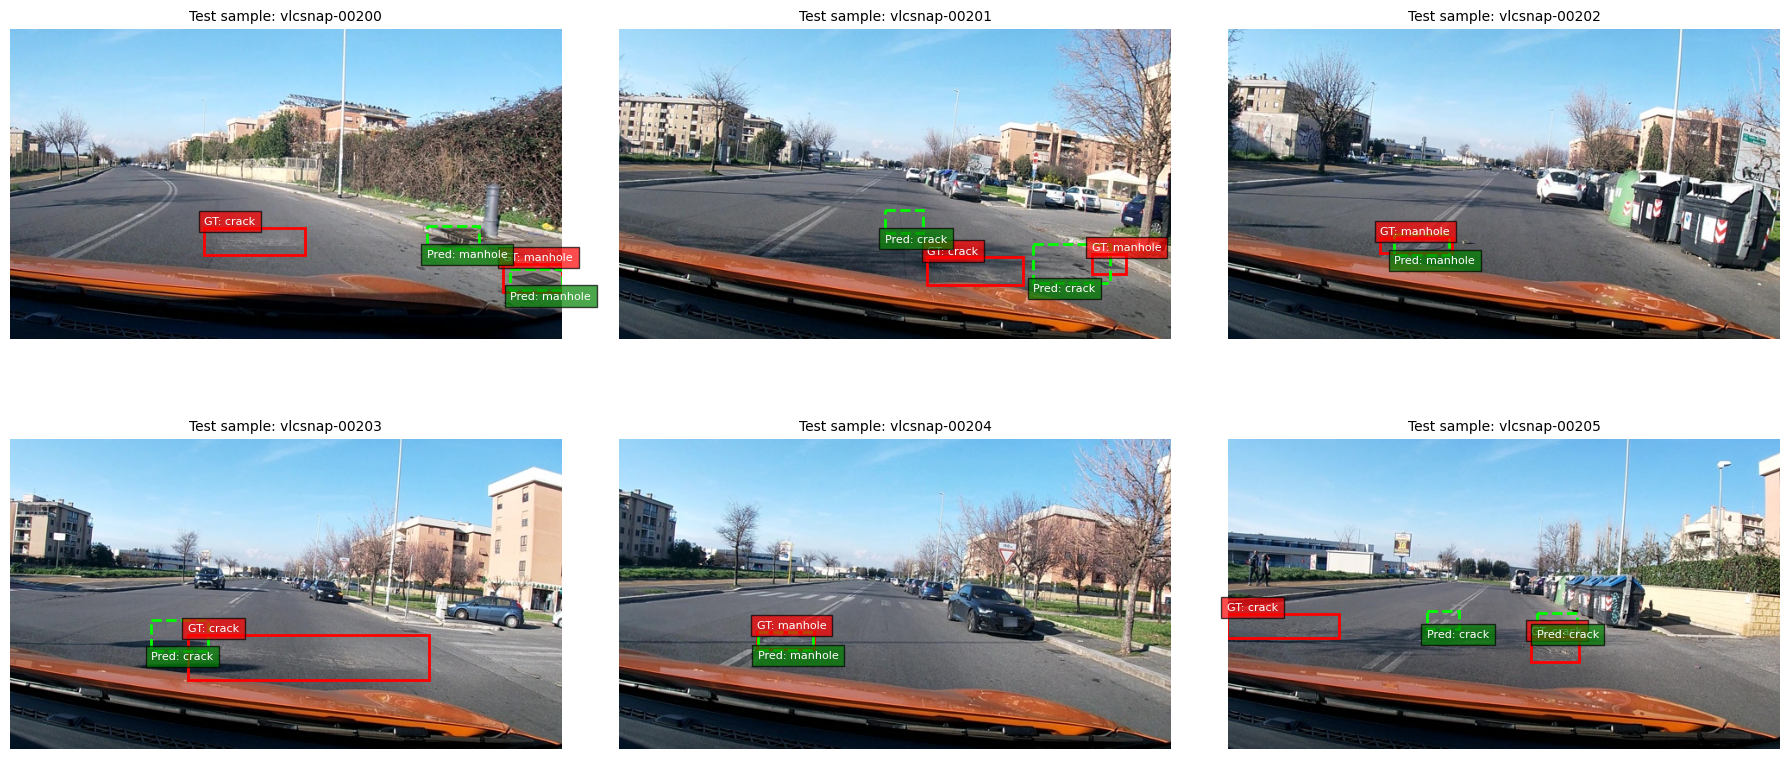

Đã lưu ảnh so sánh dự đoán tại: report/images/predictions_vs_groundtruth.png


In [49]:
# 9.1 Trực quan hoá 6 ảnh dự đoán đúng / sai
from scripts.score import parse_output

# Đọc kết quả tốt nhất (ví dụ E2 hoặc E1)
pred_rows = read_jsonl("work/e1.jsonl")
pred_dict = {r["image_id"]: r["raw"] for r in pred_rows}

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()

for i, sample in enumerate(test_samples[:6]):
    ax = axes[i]
    img = Image.open(f"data/{sample['image_path']}").convert("RGB")
    w, h = img.size
    ax.imshow(img)

    # Vẽ Ground Truth (Nét liền đỏ)
    for obj in sample["objects"]:
        xc, yc, bw, bh = obj["yolo"]
        x1, y1 = (xc - bw / 2) * w, (yc - bh / 2) * h
        ax.add_patch(patches.Rectangle((x1, y1), bw * w, bh * h, linewidth=2, edgecolor="red", facecolor="none"))
        ax.text(x1, y1 - 4, f"GT: {obj['label']}", color="white", fontsize=8, bbox=dict(facecolor="red", alpha=0.7))

    # Vẽ Dự đoán (Nét đứt xanh lá)
    raw = pred_dict.get(sample["image_id"], "")
    preds = parse_output(raw)
    if preds:
        for p in preds:
            bx1, by1, bx2, by2 = p["bbox"]
            px1, py1 = bx1 * w / 1000.0, by1 * h / 1000.0
            pw, ph = (bx2 - bx1) * w / 1000.0, (by2 - by1) * h / 1000.0
            ax.add_patch(patches.Rectangle((px1, py1), pw, ph, linewidth=2, edgecolor="lime", linestyle="--", facecolor="none"))
            ax.text(px1, py1 + ph + 10, f"Pred: {p['label']}", color="white", fontsize=8, bbox=dict(facecolor="green", alpha=0.7))

    ax.set_title(f"Test sample: {sample['image_id']}", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.savefig("report/images/predictions_vs_groundtruth.png", dpi=150)
plt.show()
print("Đã lưu ảnh so sánh dự đoán tại: report/images/predictions_vs_groundtruth.png")


In [51]:
# 9.2 Chạy công cụ tự kiểm tra nghiệm thu
!python /content/drive/MyDrive/K4-Track-4-Day10-VisionLanguageModel/scripts/check_submission.py


[FAIL] evidence e0 — thiếu report/evidence/e0.json
[FAIL] evidence e1 — thiếu report/evidence/e1.json
[FAIL] evidence e2 — thiếu report/evidence/e2.json
[FAIL] evidence e3 — thiếu report/evidence/e3.json
[FAIL] evidence e4 — cần ít nhất một file e4*.json
[PASS] dataset_version nhất quán — []
[WARN] khớp data/splits/meta.json — không có data/splits/meta.json để đối chiếu
[FAIL] REPORT.md đã điền — còn chuỗi '<điền'
[FAIL] git commits — 1/5
[PASS] git forbidden files

7 FAIL, 1 WARN
